# 一个共轭骨架的能隙，能承受多大的键耦合变化？

研究种子 v0.2 · 2026-10-18 · 已执行的模型计算，新颖性尚未确立。

**v0.2 做了什么**

- **重新定位。** v0.1 的"带符号 Kekulé 展开"就是 Dewar–Longuet-Higgins 的 algebraic structure count（ASC）：$|\det T|$ 等于正负 Kekulé 项相消后的计数。因此 ρ 的准确说法是：**ASC 中正负项的相消，在每条键耦合独立浮动时能撑多大扰动。**
- **两处数学补充。** 顶点枚举本身就是完整证明（第 1 节）；联苯撑的临界方程可化为 $q^3+q=1$（第 2 节）。
- **新算法。** 用 Rohn 的 $(y,z)$ 顶点判据加广义本征值，代价是 $2^{2n-1}$ 个小本征问题（n 为原子数的一半），与键数无关，能处理有多个负号项的分子。已与全顶点枚举逐个对拍（第 5 节）。
- **新数据。** [N]phenylene 系列，N = 2–4，共 9 个可闭合骨架的精确 ρ（第 6 节）。
- **第二道关的第一次检验。** Hückel 加 σ 弹簧的键长模型（SSH 类），问：分子自己往哪里弛豫？最省能的闭合要多少能量？（第 7 节）

**运行时间：** 在 2 核机器上约 11 分钟，大头是 [4]phenylene 的精确 ρ（每个约 2 分钟）。

**这一版的结论先放前面**（数字见各节输出）：

1. 定义（regularity radius）和符号展开（ASC）都是已知理论。能主张的新东西，最多是"ASC 的扰动鲁棒性"及其化学解读。
2. 五个同原子数的 [4]phenylene 异构体中，ρ、gap、ASC 给出**完全相同的排序**（ρ 还把螺旋型与锯齿型并列）。在同尺寸异构体排序上，ρ 没有带来 gap 之外的信息。
3. 跨尺寸出现一对反转：联苯撑的 gap 比角型 [3]phenylene 大，ρ 却更小。键长模型的闭合能量站在 ρ 这一边。
4. 键长模型里，所有 9 个分子的自发弛豫都**把 gap 撑大**，不是推向闭合。最省能的闭合几何也比弛豫基态高约 1.9–5.6 eV（K = 43）。基态热涨落到不了那里。
5. 9 个分子里，闭合能量与 ρ 的秩相关为 0.95，与均匀几何 gap 为 0.90，与弛豫后 gap 只有 0.40–0.78。**弛豫后的 gap 有多大，不能说明它有多难被关掉。** 这是目前最接近"新增信息"的观察，但样本只有 9 个且同属一类，ρ 相对均匀 gap 的优势只靠一两对分子。


## 1. 模型与指标

**问题：** 固定分子连接关系，让每条现有键的 π 跃迁积分独立变化不超过同一个比例，最小需要变化多少，才能让 Hückel HOMO–LUMO gap 变成零？

这是模型内可严格定义的结构鲁棒性问题。它不等于芳香性判据、化学稳定性、实验激发能或真实分子的可实现形变。

考虑连通、平衡二分图，每个顶点一个 p 轨道、一个 π 电子；忽略重叠和电子相互作用，统一在位能取零。选取单位 $|\beta|=1$：

$$H=-\begin{pmatrix}0&T\\T^\mathsf{T}&0\end{pmatrix},\qquad g=2\sigma_{\min}(T).$$

初始每条边权重为 1。定义

$$\rho=\inf\{\epsilon\ge0:\exists E,\ |E_{ij}|\le\epsilon T_{ij},\ \det(T+E)=0\}.$$

零元素不能改变；每条无向键在 H 的两个对称位置同步变化。对于 $\epsilon<1$，所有现有耦合保持正值。这里的 $\rho$ 就是具有指定零结构的 **interval-matrix regularity radius**，不是新定义。一般矩阵上计算它是 NP-hard（Poljak & Rohn 1993）。

**与 ASC 的关系。** 展开 $\det T$，每个非零项对应一个完美匹配（Kekulé 结构），带排列符号。两个 Kekulé 结构之差由若干共轭圈组成：圈长为 4n 的使符号翻转，4n+2 的不翻转。$|\det T|$ 就是 Dewar & Longuet-Higgins（1952）、Wilcox（1968, 1969）讨论的 algebraic structure count。等权重时 ρ 问的是：**让这种正负相消恰好抵消到零，需要多大的局部键耦合差异。**

**适用范围。** 没有 4n 共轭圈的体系（所有苯型烃）各项同号，在 $\epsilon<1$ 内永远不能闭合，按定义 ρ = 1。ρ 只对含 4n 圈的交替烃有分辨力。

**顶点枚举就是证明。** 每个完美匹配对每条边最多用一次，所以 $\det(T+E)$ 对每条边权都是仿射函数，整体是多线性的。多线性函数在超立方体上的最小值落在顶点，因此"在 $\rho(1-\delta)$ 处所有顶点 det > 0、在 $\rho(1+\delta)$ 处某个顶点 det < 0"本身就严格确定了 ρ。

最朴素的比较基线：$\rho\ge\sigma_{\min}(T)/\|T\|_2$，由 $\|E\|_2\le\epsilon\|T\|_2$ 和奇异值扰动界得到。


## 2. 两个可解析核验的非苯型例子

令 $m=1-\epsilon,p=1+\epsilon,q=m/p$。

**苯并环丁二烯：** 两项正、一项负（K = 3，ASC = 1）。将正项除以唯一负项的绝对值，每个比值的全局下界分别是 $q^2,q^4$，并能由同一个边权配置同时取到。临界条件为

$$q^2+q^4=1\iff q^2=1/\varphi,\qquad\rho=\frac{\sqrt{\varphi}-1}{\sqrt{\varphi}+1}=0.119725922956805\ldots$$

**联苯撑：** 四项正、一项负（K = 5，ASC = 3）。四个比值的同时可达下界是 $q^2,q^4,q^4,q^6$，于是

$$q^2+2q^4+q^6=q^2(1+q^2)^2=1\iff q^3+q-1=0,\qquad\rho=0.188828952032499\ldots$$

q 是 $x^3+x=1$ 的唯一实根，约 0.682328。比值下界证明在更小的参数盒里没有零点，同时可达的配置给出边界零点。

**对照：** 苯和萘的所有匹配项同号（ASC = K），正权重下 $\det T$ 不会为零，ρ = 1。这不意味着它们的 gap 不会缩小。

下面的代码是 v0.1 原样保留的验证（只适用于恰有一个负项的分子），之后一格核对两个闭式。


In [1]:
import io
import numpy as np
import matplotlib.pyplot as plt
from itertools import permutations, product
from scipy.optimize import brentq

def ring(n):
    return n, [(i, (i+1)%n) for i in range(n)]

def fuse(graph, edge, ring_size):
    n, edges = graph
    u, v = edge
    path = [u] + list(range(n, n+ring_size-2)) + [v]
    return n+ring_size-2, edges + list(zip(path[:-1],path[1:]))

def block(graph):
    n, edges = graph
    adj = [[] for _ in range(n)]
    for u,v in edges:
        adj[u].append(v); adj[v].append(u)
    color, queue = {0:0}, [0]
    for u in queue:
        for v in adj[u]:
            if v not in color:
                color[v] = 1-color[u]; queue.append(v)
            assert color[v] != color[u]
    assert len(color) == n
    left = [i for i in range(n) if color[i] == 0]
    right = [i for i in range(n) if color[i] == 1]
    assert len(left) == len(right)
    A = np.zeros((n,n))
    for u,v in edges: A[u,v] = A[v,u] = 1
    return A[np.ix_(left,right)], left, right

models = {
    'Benzene':ring(6),
    'Naphthalene':fuse(ring(6),(0,1),6),
    'Benzocyclobutadiene':fuse(ring(4),(0,1),6),
    'Biphenylene':fuse(fuse(ring(4),(0,1),6),(2,3),6)
}

def matching_terms(T, edges):
    terms = []
    for perm in permutations(range(len(T))):
        if all(T[i,perm[i]] for i in range(len(T))):
            inversions = sum(perm[i] > perm[j]
                             for i in range(len(T)) for j in range(i+1,len(T)))
            terms.append(((-1)**inversions,
                          [edges.index((i,perm[i])) for i in range(len(T))]))
    return terms

results = {}
for name, graph in models.items():
    T, left, right = block(graph)
    edges = list(zip(*np.nonzero(T)))
    terms = matching_terms(T, edges)
    orientation = int(np.sign(np.linalg.det(T)))
    terms = [(orientation*s, ix) for s,ix in terms]
    corners = np.array(list(product([-1,1], repeat=len(edges))))
    def vertex_dets(eps):
        return sum(s*np.prod(1+eps*corners[:,ix],axis=1) for s,ix in terms)
    svals = np.linalg.svd(T,compute_uv=False)
    baseline_bound = svals[-1]/svals[0]
    if all(s == 1 for s,ix in terms):
        rho, signs, exponents = 1.0, -np.ones(len(edges),int), []
    else:
        negatives = [set(ix) for s,ix in terms if s == -1]
        assert len(negatives) == 1
        negative = negatives[0]
        positive = [set(ix) for s,ix in terms if s == 1]
        exponents = [len(term-negative) for term in positive]
        # In each ratio, numerator and denominator have the same degree.
        assert all(len(term-negative) == len(negative-term) for term in positive)
        down = set().union(*(term-negative for term in positive))
        up = set().union(*(negative-term for term in positive))
        assert not down.intersection(up)  # simultaneous equality certificate
        signs = np.array([1 if i in up else -1 for i in range(len(edges))])
        q = brentq(lambda q:sum(q**k for k in exponents)-1,0,1,xtol=1e-14)
        rho = (1-q)/(1+q)
        assert np.min(vertex_dets(rho-1e-7)) > 0
        assert abs(np.min(vertex_dets(rho))) < 1e-12
        assert np.min(vertex_dets(rho+1e-7)) < 0
    witness = T.copy()
    for (i,j),sgn in zip(edges,signs): witness[i,j] = 1+rho*sgn
    assert 2*np.linalg.svd(witness,compute_uv=False)[-1] < 1e-12
    results[name] = dict(T=T,left=left,right=right,edges=edges,terms=terms,
                         rho=rho,signs=signs,exponents=exponents)
    print(f'{name:23s} gap={2*svals[-1]:.9f}  rho={rho:.12f} '
          f' norm_bound={baseline_bound:.6f}  matchings={len(terms)}')
    if exponents:
        print('  ratio exponents:',exponents)
        print('  witness edges (0-based):',
              [(left[i],right[j],int(sgn)) for (i,j),sgn in zip(edges,signs)])
print('Verified: matching certificates, all box vertices near thresholds, and SVD closure.')


Benzene                 gap=2.000000000  rho=1.000000000000  norm_bound=0.500000  matchings=2
Naphthalene             gap=1.236067977  rho=1.000000000000  norm_bound=0.268387  matchings=3
Benzocyclobutadiene     gap=0.524719390  rho=0.119725922957  norm_bound=0.111374  matchings=3
  ratio exponents: [2, 4]
  witness edges (0-based): [(0, 1, -1), (0, 3, 1), (0, 4, -1), (2, 1, 1), (2, 3, -1), (5, 4, 1), (5, 6, -1), (7, 1, -1), (7, 6, 1)]
Biphenylene             gap=0.890083736  rho=0.188828952032  norm_bound=0.175761  matchings=5
  ratio exponents: [2, 4, 4, 6]
  witness edges (0-based): [(0, 1, -1), (0, 3, 1), (0, 4, -1), (2, 1, 1), (2, 3, -1), (2, 8, -1), (5, 4, 1), (5, 6, -1), (7, 1, -1), (7, 6, 1), (9, 8, 1), (9, 10, -1), (11, 3, -1), (11, 10, 1)]
Verified: matching certificates, all box vertices near thresholds, and SVD closure.


In [2]:
phi = (1+5**.5)/2
q_bcb = phi**-0.5                                   # q^2 + q^4 = 1  <=>  q^2 = 1/phi
q_bip = brentq(lambda q: q**3 + q - 1, 0, 1)        # q^2 + 2q^4 + q^6 = q^2 (1+q^2)^2 = 1  <=>  q^3 + q = 1
for name, q in [('Benzocyclobutadiene', q_bcb), ('Biphenylene', q_bip)]:
    print(f'{name:20s} q = {q:.12f}   rho = (1-q)/(1+q) = {(1-q)/(1+q):.12f}   notebook value = {results[name]["rho"]:.12f}')
q = q_bip
print('check q^2+2q^4+q^6 =', q**2 + 2*q**4 + q**6)

Benzocyclobutadiene  q = 0.786151377757   rho = (1-q)/(1+q) = 0.119725922957   notebook value = 0.119725922957
Biphenylene          q = 0.682327803828   rho = (1-q)/(1+q) = 0.188828952032   notebook value = 0.188828952032
check q^2+2q^4+q^6 = 1.0000000000003004


## 3. 闭合见证与沿见证的 gap

红色边：$1+\epsilon$；蓝色边：$1-\epsilon$。数字为 0-based 原子编号。左、中为闭合见证；右图沿这两条固定路径绘图，**不是每个 ε 上的全局最小 gap 曲线**。画的是 π 耦合模型，坐标是示意，不是优化几何。

注意见证的规律：变强的边正是那个负号 Kekulé 结构的边。用化学语言说，关闭 gap 要把分子往反芳香的共振式上推。第 7 节检验分子本身愿不愿意往那里走。


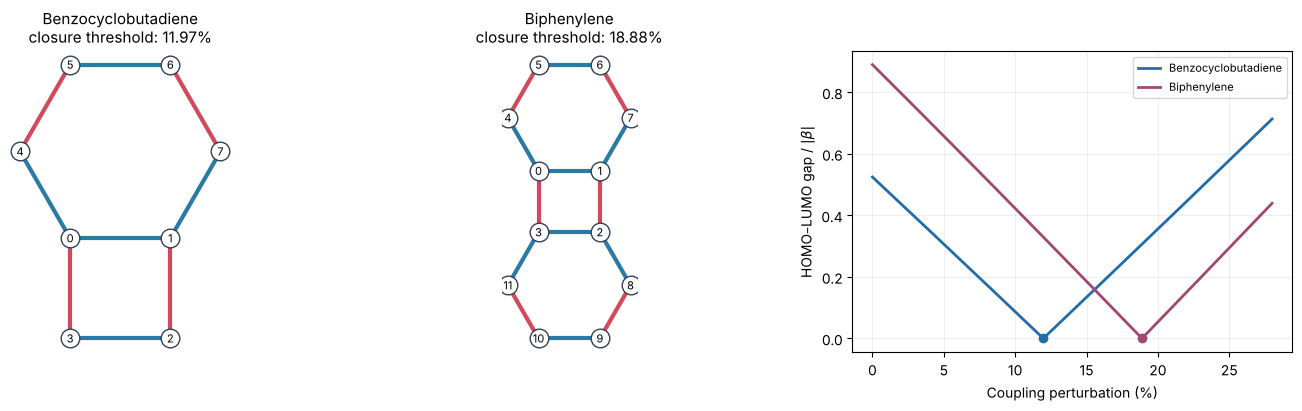

In [3]:
fig, axes = plt.subplots(1,3,figsize=(14,4),layout='constrained')
positions = {0:(0,1),1:(1,1),2:(1,0),3:(0,0),
             4:(-.5,1.866),5:(0,2.732),6:(1,2.732),7:(1.5,1.866),
             8:(1.5,-.866),9:(1,-1.732),10:(0,-1.732),11:(-.5,-.866)}
colors = ['#226caa','#a04772']
for ax,name,color in zip(axes[:2],list(results)[2:],colors):
    res = results[name]
    for (i,j),sgn in zip(res['edges'],res['signs']):
        u,v = res['left'][i],res['right'][j]
        ax.plot([positions[u][0],positions[v][0]],
                [positions[u][1],positions[v][1]],
                color='#d1495b' if sgn>0 else '#297ba3',lw=3)
    for v in range(models[name][0]):
        x,y=positions[v]
        ax.scatter(x,y,s=180,c='white',edgecolors='#334155',zorder=3)
        ax.text(x,y,str(v),ha='center',va='center',fontsize=8,zorder=4)
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(f'{name}\nclosure threshold: {100*res["rho"]:.2f}%',fontsize=11)
    epsilons=np.linspace(0,.28,350)
    gaps=[]
    for eps in epsilons:
        U=res['T'].copy()
        for (i,j),sgn in zip(res['edges'],res['signs']): U[i,j]=1+eps*sgn
        gaps.append(2*np.linalg.svd(U,compute_uv=False)[-1])
    axes[2].plot(100*epsilons,gaps,color=color,label=name,lw=2)
    axes[2].scatter([100*res['rho']],[0],color=color,zorder=5)
axes[2].set(xlabel='Coupling perturbation (%)',ylabel=r'HOMO–LUMO gap / $|\beta|$')
axes[2].legend(fontsize=8); axes[2].grid(alpha=.2)
plt.show()

## 4. 与单键问题的关系

改变单条键，对 T 是秩一更新。若 T 可逆：

$$\det(T+t e_i e_j^\mathsf{T})=\det T\,[1+t(T^{-1})_{ji}].$$

增加耦合能关闭 gap，当且仅当相应逆矩阵元素为负，阈值为 $t_*=-1/(T^{-1})_{ji}$。等耦合模型中，苯并环丁二烯某条边必须从 1 增到 2，联苯撑从 1 增到 4；允许多条边协同变化后，每条所需的最大相对变化小得多。此秩一公式是经典恒等式，不主张为新成果。


## 5. 能处理多个负号项的精确算法

v0.1 的比值证书假定只有一个负号 Kekulé 项。两个 [3]phenylene 各有 4 个，[4]phenylene 有 12–13 个，所以需要一般方法。全顶点枚举要 $2^m$ 个点（m 为键数），22 条键尚可，30 条键就跑不动。

**Rohn 判据**（见 Rohn 2009 综述）：区间矩阵 $\{T+E:|E_{ij}|\le\epsilon T_{ij}\}$ 奇异，当且仅当某个

$$A_{yz}=T-\epsilon\,D_yTD_z,\qquad y,z\in\{-1,+1\}^n$$

奇异。也就是说只需检查"每条键的增减号是 $-y_iz_j$"这一类顶点，共 $2^{2n-1}$ 个（固定 $z_1=1$ 去掉整体符号）。对固定的 $(y,z)$，$\det(T-\epsilon S)=0$ 等价于 $\epsilon=1/\lambda$，λ 是 $T^{-1}S$ 的实本征值，所以

$$\rho=\Big[\max_{y,z}\lambda_{\max}^{\mathbb R}\big(T^{-1}D_yTD_z\big)\Big]^{-1}.$$

一次扫描就得到精确值，不需要二分。代价只取决于原子数，与键数无关：[3]phenylene 约 1 秒，[4]phenylene 约 2 分钟，[5]phenylene（$2^{29}$）要数小时，目前没有算。

下面先在四个分子上与全顶点枚举对拍。


In [4]:
# ---- v0.2 library: molecular graphs with coordinates, Kekulé/ASC, exact rho, bond-length model ----
import time, json
from itertools import product
from scipy.optimize import minimize
from scipy.stats import spearmanr
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

def hexagon():
    ang = np.pi/2 - np.arange(6)*np.pi/3
    return dict(n=6, edges=[(i,(i+1)%6) for i in range(6)],
                pos=[(np.cos(a), np.sin(a)) for a in ang], rings=[list(range(6))])

def fuse_polygon(g, u, v, k):
    """Fuse a regular k-gon onto bond (u,v), on the side away from the ring that already holds it."""
    pos = np.array(g['pos'], float)
    host = next(r for r in g['rings'] if u in r and v in r)
    pu, pv = pos[u], pos[v]; mid, d = (pu+pv)/2, pv-pu
    nrm = np.array([-d[1], d[0]]); nrm /= np.linalg.norm(nrm)
    if np.dot(nrm, mid-pos[host].mean(0)) < 0: nrm = -nrm
    L = np.linalg.norm(d); c = mid + L/(2*np.tan(np.pi/k))*nrm; R = L/(2*np.sin(np.pi/k))
    a_u = np.arctan2(*(pu-c)[::-1]); a_v = np.arctan2(*(pv-c)[::-1]); step = 2*np.pi/k
    wrap = lambda x: (x+np.pi) % (2*np.pi) - np.pi
    sgn = 1 if abs(wrap(a_u + step*(k-1) - a_v)) < 1e-6 else -1
    new = list(range(g['n'], g['n']+k-2))
    newpos = [tuple(c + R*np.array([np.cos(a_u+sgn*step*(i+1)), np.sin(a_u+sgn*step*(i+1))])) for i in range(k-2)]
    path = [u]+new+[v]
    return dict(n=g['n']+k-2, edges=g['edges']+list(zip(path[:-1], path[1:])),
                pos=list(g['pos'])+newpos, rings=g['rings']+[path]), path

def phenylene(choices):
    """[N]phenylene, N = len(choices)+2. For each internal benzene: 'p' = para (linear),
    'L'/'R' = angular to either side. With this construction ['L','L'] is zigzag, ['L','R'] helical."""
    g = hexagon(); a, b = 2, 3
    for step in range(len(choices)+1):
        g, sq = fuse_polygon(g, a, b, 4)
        g, hx = fuse_polygon(g, sq[2], sq[1], 6)
        if step < len(choices):
            a, b = {'p': (hx[2], hx[3]), 'L': (hx[1], hx[2]), 'R': (hx[3], hx[4])}[choices[step]]
    return g

def triangular4():
    g = hexagon()
    for a, b in [(0,1),(2,3),(4,5)]:
        g, sq = fuse_polygon(g, a, b, 4); g, _ = fuse_polygon(g, sq[2], sq[1], 6)
    return g

def benzocyclobutadiene_g():
    g = hexagon(); g, _ = fuse_polygon(g, 2, 3, 4); return g

def naphthalene_g():
    g = hexagon(); g, _ = fuse_polygon(g, 2, 3, 6); return g

def check_geometry(g):
    P = np.array(g['pos'])
    assert all(abs(np.linalg.norm(P[u]-P[v])-1) < 1e-6 for u, v in g['edges'])
    D = np.linalg.norm(P[:,None]-P[None], axis=-1) + 10*np.eye(g['n'])
    assert D.min() > 0.5, 'overlapping atoms'
    assert np.bincount(np.array(g['edges']).ravel()).max() <= 3

def bipartite(g):
    """Return T (rows = one sublattice, cols = the other) and, for every bond in g['edges'], its (i,j) in T."""
    n, E = g['n'], g['edges']; adj = [[] for _ in range(n)]
    for u, v in E: adj[u].append(v); adj[v].append(u)
    col, q = {0: 0}, [0]
    for u in q:
        for v in adj[u]:
            if v not in col: col[v] = 1-col[u]; q.append(v)
            assert col[v] != col[u], 'not bipartite'
    L = [i for i in range(n) if col[i] == 0]; R = [i for i in range(n) if col[i] == 1]
    assert len(L) == len(R)
    li = {a: i for i, a in enumerate(L)}; ri = {a: j for j, a in enumerate(R)}
    T = np.zeros((len(L), len(R))); bix = []
    for u, v in E:
        i, j = (li[u], ri[v]) if u in li else (li[v], ri[u])
        T[i, j] = 1; bix.append((i, j))
    return T, L, R, bix

def kekule_terms(T):
    m = len(T); out = []; cols = [np.nonzero(T[i])[0] for i in range(m)]
    def rec(i, used, perm):
        if i == m:
            inv = sum(perm[a] > perm[b] for a in range(m) for b in range(a+1, m))
            out.append(((-1)**inv, tuple(perm))); return
        for j in cols[i]:
            if j not in used: rec(i+1, used | {j}, perm+[j])
    rec(0, frozenset(), [])
    sgn = int(np.sign(np.linalg.det(T)))
    return [(sgn*s, p) for s, p in out]

def structure_counts(T):
    """K = number of Kekulé structures; ASC = |det T| = algebraic structure count; neg = # negative terms."""
    terms = kekule_terms(T)
    return len(terms), abs(sum(s for s, _ in terms)), sum(1 for s, _ in terms if s < 0)

def rho_rohn(T, chunk=1 << 15):
    """Exact closure threshold via Rohn's (y,z)-vertex criterion.
    The interval matrix {T + E : |E_ij| <= eps*T_ij} is singular iff some
    A_yz = T - eps*D_y T D_z (y, z in {-1,+1}^n) is singular. det(T - eps*S) = 0 <=> eps = 1/lambda,
    lambda a real eigenvalue of T^{-1} S, so rho = 1 / max over (y,z) of the largest real lambda.
    Cost: 2^(2n-1) small eigenproblems (n = half the atom count), independent of the bond count."""
    n = len(T); Ti = np.linalg.inv(T); best, arg = 1.0, None
    ys = np.array(list(product([-1, 1], repeat=n)), float)
    zs = np.hstack([np.ones((2**(n-1), 1)), np.array(list(product([-1, 1], repeat=n-1)), float)])
    A = np.einsum('ij,yj,jk->yik', Ti, ys, T)
    zper = max(1, chunk // len(ys))
    for zb in range(0, len(zs), zper):
        Z = zs[zb:zb+zper]
        lam = np.linalg.eigvals((A[None]*Z[:, None, None, :]).reshape(-1, n, n))
        lmax = np.where(np.abs(lam.imag) < 1e-9, lam.real, -np.inf).max(axis=1)
        k = int(np.argmax(lmax))
        if lmax[k] > max(1/best, 1 + 1e-4) + 1e-12:
            best = 1/lmax[k]; iz, iy = divmod(k, len(ys)); arg = (ys[iy].copy(), Z[iz].copy())
    return best, arg

def rho_vertices(T):
    """Brute force over all 2^m box vertices (m = bonds). det is affine in every bond weight,
    so its minimum over the box sits on a vertex: this alone is a complete proof."""
    terms = kekule_terms(T); edges = list(zip(*np.nonzero(T))); eix = {e: k for k, e in enumerate(edges)}
    tix = [(s, [eix[(i, p[i])] for i in range(len(T))]) for s, p in terms]
    if all(s > 0 for s, _ in tix): return 1.0
    m = len(edges)
    def mindet(eps):
        mn = np.inf
        for start in range(0, 1 << m, 1 << 16):
            idx = np.arange(start, min(start + (1 << 16), 1 << m))
            S = ((idx[:, None] >> np.arange(m)) & 1)*2-1
            mn = min(mn, sum(s*np.prod(1+eps*S[:, ix], axis=1) for s, ix in tix).min())
        return mn
    return brentq(mindet, 1e-6, 0.9999, xtol=1e-13)

def rho_local(T, restarts=60, seed=0):
    """Hill-climbing over Rohn sign vectors: an upper bound only, used to show why exactness matters."""
    n = len(T); Ti = np.linalg.inv(T); rng = np.random.default_rng(seed)
    def lam(y, z):
        l = np.linalg.eigvals(Ti @ (T*np.outer(y, z))); l = l.real[np.abs(l.imag) < 1e-9]
        return l.max() if len(l) else -np.inf
    best = -np.inf
    for _ in range(restarts):
        y = rng.choice([-1., 1.], n); z = rng.choice([-1., 1.], n); v = lam(y, z); improved = True
        while improved:
            improved = False
            for vec in (y, z):
                for k in range(n):
                    vec[k] *= -1; w = lam(y, z)
                    if w > v + 1e-12: v = w; improved = True
                    else: vec[k] *= -1
        best = max(best, v)
    return 1/best if best > 1 + 1e-4 else 1.0

class BondModel:
    """Hückel pi + harmonic sigma springs.  t_b = t0 - alpha*delta_b ;
    E = -2 * sum(singular values of the weighted T) + sum_b (K/2 delta_b^2 + c delta_b),
    with c = -2*alpha*p_ref so that benzene (bond order 2/3) is stationary at delta = 0.
    At equilibrium delta_b = 2*alpha*(p_ref - p_b)/K: a Coulson-type bond-order/bond-length line
    with slope 2*alpha/K (0.19 A per unit bond order for K = 43). Units: eV, angstrom."""
    def __init__(self, g, t0=2.5, alpha=4.1, K=43.0, p_ref=2/3):
        self.T0, self.L, self.R, self.bix = bipartite(g)
        self.t0, self.a, self.K, self.c = t0, alpha, K, -2*alpha*p_ref
        self.ii = np.array([i for i, j in self.bix]); self.jj = np.array([j for i, j in self.bix]); self.m = len(self.bix)
    def Tw(self, d):
        T = np.zeros_like(self.T0); T[self.ii, self.jj] = self.t0 - self.a*d; return T
    def energy(self, d):
        U, s, Vt = np.linalg.svd(self.Tw(d)); p = (U @ Vt)[self.ii, self.jj]
        return -2*s.sum() + np.sum(0.5*self.K*d**2 + self.c*d), 2*self.a*p + self.K*d + self.c
    def gap(self, d): return 2*np.linalg.svd(self.Tw(d), compute_uv=False)[-1]
    def det(self, d):
        U, s, Vt = np.linalg.svd(self.Tw(d)/self.t0); sg = np.linalg.det(U)*np.linalg.det(Vt)
        cof = np.array([np.prod(np.delete(s, k)) for k in range(len(s))])
        adjT = sg*(U*cof) @ Vt
        return sg*np.prod(s), adjT[self.ii, self.jj]*(-self.a/self.t0)
    def relax(self):
        r = minimize(self.energy, np.zeros(self.m), jac=True, method='BFGS', options=dict(gtol=1e-9, maxiter=5000))
        return r.x, r.fun
    def closure(self, starts):
        """Lowest-energy geometry found with det(T) = 0, i.e. Hückel gap exactly zero (multi-start SLSQP)."""
        best = None; bnd = [(-0.8*self.t0/self.a, 0.8*self.t0/self.a)]*self.m
        for d0 in starts:
            r = minimize(self.energy, d0, jac=True, method='SLSQP', bounds=bnd,
                         constraints=[dict(type='eq', fun=lambda d: self.det(d)[0], jac=lambda d: self.det(d)[1])],
                         options=dict(ftol=1e-12, maxiter=1000))
            if r.success and abs(self.det(r.x)[0]) < 1e-8 and (best is None or r.fun < best.fun): best = r
        return best

# palette: diverging blue <-> neutral gray <-> red ; three categorical slots
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])
FAMILY_COLOR = {'reference': '#1baf7a', 'linear': '#2a78d6', 'angular/branched': '#eb6834'}

def draw_bonds(ax, g, values=None, norm=None, cmap=DIV, lw=3.4, alpha=None):
    P = np.array(g['pos'])
    for k, (u, v) in enumerate(g['edges']):
        c = '#475569' if values is None else cmap(norm(values[k]))
        ax.plot(*P[[u, v]].T, color=c, lw=lw, solid_capstyle='round', zorder=2,
                alpha=1 if alpha is None else alpha[k])
    ax.scatter(P[:, 0], P[:, 1], s=10, color='#1f2937', zorder=3)
    ax.set_aspect('equal'); ax.axis('off')

print('library loaded')

library loaded


In [5]:
check_v01 = {'Benzocyclobutadiene': benzocyclobutadiene_g(), 'Biphenylene': phenylene([]),
             'linear[3]phenylene': phenylene(['p']), 'angular[3]phenylene': phenylene(['L'])}
print(f'{"molecule":22s}{"bonds":>6s}{"Rohn (exact)":>18s}{"t/s":>7s}{"all box vertices":>20s}{"t/s":>7s}')
for name, g in check_v01.items():
    check_geometry(g); T, *_ = bipartite(g)
    t = time.time(); r1, _ = rho_rohn(T); t1 = time.time()-t
    t = time.time(); r2 = rho_vertices(T); t2 = time.time()-t
    assert abs(r1-r2) < 1e-10
    print(f'{name:22s}{len(g["edges"]):6d}{r1:18.12f}{t1:7.1f}{r2:20.12f}{t2:7.1f}')
print('Rohn criterion agrees with full vertex enumeration to 1e-10 on all four.')

molecule               bonds      Rohn (exact)    t/s    all box vertices    t/s
Benzocyclobutadiene        9    0.119725922957    0.0      0.119725922957    0.0
Biphenylene               14    0.188828952032    0.0      0.188828952032    0.1


linear[3]phenylene        22    0.119725922957    1.0      0.119725922957   46.2


angular[3]phenylene       22    0.196160558133    1.0      0.196160558133   52.9
Rohn criterion agrees with full vertex enumeration to 1e-10 on all four.


## 6. [N]phenylene 系列

N 个苯环由 N−1 个四元环连接。内部苯环可以对位稠合（线型），或间位稠合（角型，左右两种）。N = 4 时得到线型、bent（一个对位一个间位）、螺旋型、锯齿型，外加三臂的 triangular [4]phenylene。所有骨架都检查了键长、原子不重叠和最大配位数 3。

表中最后一列是对 Rohn 符号做贪心爬山得到的值。它只是上界：在 zigzag[4] 上它漏掉了真正的最小值，这说明精确求解不是洁癖。


In [6]:
mols = {
 'benzene': (hexagon(), 'reference'), 'naphthalene': (naphthalene_g(), 'reference'),
 'benzocyclobutadiene': (benzocyclobutadiene_g(), 'reference'),
 'biphenylene': (phenylene([]), 'linear'),
 'linear[3]': (phenylene(['p']), 'linear'), 'angular[3]': (phenylene(['L']), 'angular/branched'),
 'linear[4]': (phenylene(['p','p']), 'linear'), 'bent[4]': (phenylene(['p','L']), 'angular/branched'),
 'helical[4]': (phenylene(['L','R']), 'angular/branched'), 'zigzag[4]': (phenylene(['L','L']), 'angular/branched'),
 'triangular[4]': (triangular4(), 'angular/branched')}
S = {}
t_all = time.time()
for name, (g, fam) in mols.items():
    check_geometry(g); T, L, R, bix = bipartite(g)
    r, yz = rho_rohn(T); K, ASC, neg = structure_counts(T); sv = np.linalg.svd(T, compute_uv=False)
    S[name] = dict(g=g, fam=fam, T=T, L=L, R=R, bix=bix, rho=r, yz=yz, K=K, ASC=int(ASC), neg=neg,
                   gap=2*sv[-1], normbound=sv[-1]/sv[0],
                   rho_local=rho_local(T) if r < 1 else 1.0)
print(f'exact thresholds for {len(S)} molecules in {time.time()-t_all:.0f} s\n')
print(f'{"molecule":20s}{"atoms":>6s}{"K":>4s}{"ASC":>5s}{"neg":>5s}{"gap/|b|":>9s}{"rho":>10s}{"norm bnd":>10s}{"local srch":>11s}')
for name, d in S.items():
    flag = '  <- local search misses' if d['rho_local'] - d['rho'] > 1e-6 else ''
    print(f'{name:20s}{d["g"]["n"]:6d}{d["K"]:4d}{d["ASC"]:5d}{d["neg"]:5d}{d["gap"]:9.4f}{d["rho"]:10.5f}'
          f'{d["normbound"]:10.4f}{d["rho_local"]:11.5f}{flag}')

exact thresholds for 11 molecules in 525 s

molecule             atoms   K  ASC  neg  gap/|b|       rho  norm bnd local srch
benzene                  6   2    2    0   2.0000   1.00000    0.5000    1.00000
naphthalene             10   3    3    0   1.2361   1.00000    0.2684    1.00000
benzocyclobutadiene      8   3    1    1   0.5247   0.11973    0.1114    0.11973
biphenylene             12   5    3    1   0.8901   0.18883    0.1758    0.18883
linear[3]               18  12    4    4   0.5247   0.11973    0.0996    0.11973
angular[3]              18  13    5    4   0.8441   0.19616    0.1584    0.19616
linear[4]               24  29    5   12   0.3484   0.07558    0.0651    0.07558
bent[4]                 24  31    7   12   0.5651   0.12647    0.1048    0.12647
helical[4]              24  34    8   13   0.7028   0.16140    0.1293    0.16140
zigzag[4]               24  34    8   13   0.7426   0.16140    0.1367    0.16664  <- local search misses
triangular[4]           24  35    9   13 

In [7]:
iso = ['linear[4]', 'bent[4]', 'helical[4]', 'zigzag[4]', 'triangular[4]']
print('[4]phenylene isomers (same atom count):')
for key in ('gap', 'ASC', 'rho'):
    order = sorted(iso, key=lambda n: S[n][key])
    print(f'  ascending {key:4s}: ' + ' < '.join(f'{n}({S[n][key]:.3f})' if key != 'ASC' else f'{n}({S[n][key]})' for n in order))
closing = [n for n in S if S[n]['rho'] < 1]
print('\nAll molecules that can close, pairs ordered oppositely by gap and rho:')
for i, a in enumerate(closing):
    for b in closing[i+1:]:
        dg, dr = S[a]['gap'] - S[b]['gap'], S[a]['rho'] - S[b]['rho']
        if dg*dr < 0 and abs(dr) > 1e-9:
            print(f'  {a:12s} vs {b:12s}: gap {S[a]["gap"]:.3f} vs {S[b]["gap"]:.3f} ; rho {S[a]["rho"]:.4f} vs {S[b]["rho"]:.4f}')
print('Ties in rho with different gaps:')
for i, a in enumerate(closing):
    for b in closing[i+1:]:
        if abs(S[a]['rho']-S[b]['rho']) < 1e-9 and abs(S[a]['gap']-S[b]['gap']) > 1e-6:
            print(f'  {a} = {b}: rho {S[a]["rho"]:.6f}; gap {S[a]["gap"]:.3f} vs {S[b]["gap"]:.3f}')

[4]phenylene isomers (same atom count):
  ascending gap : linear[4](0.348) < bent[4](0.565) < helical[4](0.703) < zigzag[4](0.743) < triangular[4](0.905)
  ascending ASC : linear[4](5) < bent[4](7) < helical[4](8) < zigzag[4](8) < triangular[4](9)
  ascending rho : linear[4](0.076) < bent[4](0.126) < helical[4](0.161) < zigzag[4](0.161) < triangular[4](0.203)

All molecules that can close, pairs ordered oppositely by gap and rho:
  biphenylene  vs angular[3]  : gap 0.890 vs 0.844 ; rho 0.1888 vs 0.1962
Ties in rho with different gaps:
  helical[4] = zigzag[4]: rho 0.161395; gap 0.703 vs 0.743


**读法。**

- 线型系列 ρ 随长度单调下降（联苯撑 → 线型[3] → 线型[4]）。这与 Vollhardt（1993）综述的实验观察方向一致：线型系列越长越活泼、吸收越红移。但 gap 给出同样的趋势，所以这只是"没有被打脸"。
- 五个 [4]phenylene 异构体原子数相同，ρ、gap、ASC 三者排序完全一致。**在同尺寸异构体比较上，ρ 没有提供 gap 之外的信息。** 这是第三道关的一个负面结果，照实记下。
- 反转只出现在跨尺寸比较中：联苯撑对角型 [3]phenylene。
- 两组精确并列：苯并环丁二烯 = 线型 [3]phenylene，螺旋型 = 锯齿型 [4]phenylene，各自的 gap 却不同（前一组 gap 也相同，见下）。


In [8]:
def A_of(g):
    M = np.zeros((g['n'], g['n']))
    for u, v in g['edges']: M[u, v] = M[v, u] = 1
    return M
e_bcb = np.linalg.eigvalsh(A_of(S['benzocyclobutadiene']['g']))
e_lin = np.linalg.eigvalsh(A_of(S['linear[3]']['g']))
print('benzocyclobutadiene spectrum:', np.round(e_bcb, 5))
print('every one of them in linear[3]phenylene:', all(np.min(abs(e_lin - x)) < 1e-10 for x in e_bcb))

benzocyclobutadiene spectrum: [-2.35567 -1.47726 -1.09529 -0.26236  0.26236  1.09529  1.47726  2.35567]
every one of them in linear[3]phenylene: True


**苯并环丁二烯 = 线型 [3]phenylene 的原因。** 线型 [3]phenylene 有一个垂直于长轴的镜面，穿过中心苯环上不参与稠合的两个原子。对这个镜面反对称的轨道在这两个原子上振幅为零，于是两半互不耦合，每一半（外侧苯环加中心环上的两个原子）恰好是苯并环丁二烯。所以苯并环丁二烯的全部谱都包含在线型 [3]phenylene 中，gap 相同。

对 ρ 来说，对称的扰动保持这种分块，苯并环丁二烯的闭合见证可以直接搬过来，所以 $\rho_{\text{线型[3]}}\le\rho_{\text{BCB}}$。反方向（不对称扰动不能做得更好）目前只有精确计算的数值证据，没有证明。螺旋型与锯齿型的并列还没有解释。


**闭合发生在哪里。** 在精确见证处，$T$ 的左右零奇异向量给出那个降到零能量的轨道。下图圆圈面积是它在每个原子上的权重，键的颜色是见证处的耦合变化。


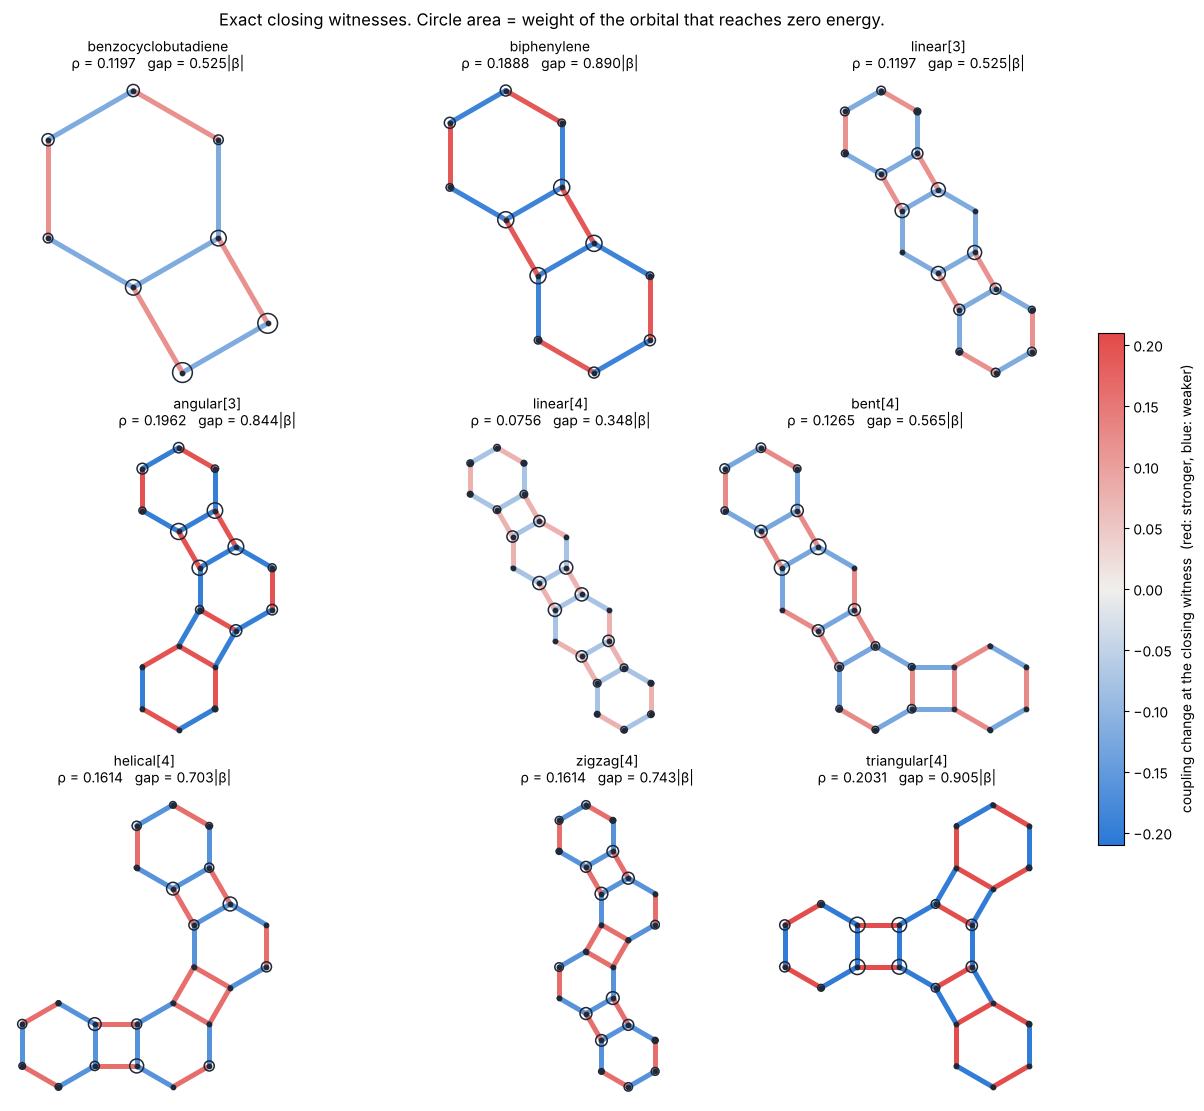

In [9]:
def zero_mode(d):
    """At the exact witness, left/right null vectors of T give the closing orbital; return per-atom weight."""
    y, z = d['yz']; W = d['T'] - d['rho']*(d['T']*np.outer(y, z))
    U, s, Vt = np.linalg.svd(W); w = np.zeros(d['g']['n'])
    w[d['L']] = U[:, -1]**2; w[d['R']] = Vt[-1]**2
    return W, w/2                                                     # weights sum to 1

fig, axes = plt.subplots(3, 3, figsize=(13, 11), layout='constrained')
norm = TwoSlopeNorm(vcenter=0, vmin=-0.21, vmax=0.21)
for ax, name in zip(axes.ravel(), closing):
    d = S[name]; W, w = zero_mode(d)
    rel = np.array([W[i, j]-1 for i, j in d['bix']])                 # relative coupling change at the witness
    draw_bonds(ax, d['g'], rel, norm, lw=3.6)
    P = np.array(d['g']['pos'])
    ax.scatter(P[:, 0], P[:, 1], s=900*w, facecolor='none', edgecolor='#1f2937', lw=1.1, zorder=4)
    ax.set_title(f'{name}\nρ = {d["rho"]:.4f}   gap = {d["gap"]:.3f}|β|', fontsize=10)
sm = plt.cm.ScalarMappable(norm=norm, cmap=DIV)
fig.colorbar(sm, ax=axes, shrink=0.5, label='coupling change at the closing witness  (red: stronger, blue: weaker)')
fig.suptitle('Exact closing witnesses. Circle area = weight of the orbital that reaches zero energy.', fontsize=12)
plt.show()

In [10]:
print('Share of the closing orbital on each ring (rings in construction order: first benzene, then square, benzene, ...):')
for name in closing:
    d = S[name]; _, w = zero_mode(d)
    shares = [sum(w[a] for a in rg) for rg in d['g']['rings']]
    tot = sum(shares)
    print(f'  {name:20s}' + ' '.join(f'{("B" if len(rg)==6 else "S")}{s/tot:5.2f}' for rg, s in zip(d['g']['rings'], shares)))

Share of the closing orbital on each ring (rings in construction order: first benzene, then square, benzene, ...):
  benzocyclobutadiene B 0.43 S 0.57
  biphenylene         B 0.31 S 0.37 B 0.31
  linear[3]           B 0.16 S 0.21 B 0.26 S 0.21 B 0.16
  angular[3]          B 0.28 S 0.33 B 0.29 S 0.07 B 0.03
  linear[4]           B 0.08 S 0.12 B 0.19 S 0.22 B 0.19 S 0.12 B 0.08
  bent[4]             B 0.19 S 0.25 B 0.24 S 0.14 B 0.12 S 0.04 B 0.02
  helical[4]          B 0.15 S 0.19 B 0.15 S 0.02 B 0.15 S 0.19 B 0.15
  zigzag[4]           B 0.15 S 0.19 B 0.14 S 0.02 B 0.14 S 0.19 B 0.15
  triangular[4]       B 0.27 S 0.07 B 0.02 S 0.07 B 0.02 S 0.30 B 0.25


角型 [3]phenylene、bent[4] 和 triangular[4] 的闭合轨道集中在一端的"苯–四元环–苯"单元上，分子其余部分几乎不参与；线型分子的闭合轨道则铺满整条链。锯齿型和螺旋型的中心四元环几乎是空的，轨道对称地分在两端。

这给出一个可以继续追的结构图像：**线型骨架的闭合是集体的，随长度越来越容易；角型和支化骨架的闭合是局域的，由最弱的那个末端单元决定。** 不过锯齿型 [4] 的 ρ（0.161）低于角型 [3]（0.196），说明"局域"不等于"与尺寸无关"，这个图像还需要更多分子来检验。


## 7. 第二道关：分子自己往哪里走？

参数盒只问"数学上能不能闭合"。要问化学上能不能到达，至少要让键耦合跟着键长走，并让键长的改变付出能量。这里用最简单的版本：

$$t_b=t_0-\alpha\,\delta_b,\qquad E=E_\pi(t)+\sum_b\Big(\tfrac{K}{2}\delta_b^2+c\,\delta_b\Big),\qquad c=-2\alpha p_{\text{ref}}.$$

- $\delta_b$ 是键 b 相对共同参考键长的改变（Å），$E_\pi=-2\sum_k\sigma_k$ 是闭壳层 Hückel π 能量。
- c 的选取让苯（键级 2/3）恰好停在 $\delta=0$。于是平衡时 $\delta_b=2\alpha(p_{\text{ref}}-p_b)/K$，即 Coulson 型的键级–键长直线。
- $t_0=2.5$ eV，$\alpha=4.1$ eV/Å（SSH 1979 的取值）。K = 43 eV/Å² 时斜率 $2\alpha/K\approx0.19$ Å/键级，与经验键级–键长关系的量级相当；K = 21（SSH 原值，偏软）和 60（偏硬）用来看结论是否依赖参数。

对每个分子计算三样东西：

1. **弛豫基态：** 对所有 $\delta_b$ 最小化 E。看 gap 是变大还是变小。
2. **最省能的闭合几何：** 在约束 $\det T(\delta)=0$ 下最小化 E（多起点 SLSQP，起点包括精确见证本身）。$\Delta E$ 是它比弛豫基态高出多少。
3. **精确见证的能量：** 把第 6 节的 L∞ 最优见证换算成键长，看它要多少能量。

**这个模型的局限，要先说清楚：** 闭壳层 Hückel 在 gap 接近零时并不可靠，真实分子会变成开壳层，电子相关会降低能量，所以这里的 ΔE 偏高；σ 骨架只是谐振弹簧，不含角应变和四元环张力；多起点优化给出的是局部最优，ΔE 严格说是模型内最小闭合能量的上界。它适合用来看方向和排序，不适合报绝对能量。


In [11]:
KS = (21.0, 43.0, 60.0)
H = {}
t_all = time.time()
for name in closing:
    d = S[name]; y, z = d['yz']; H[name] = {}
    for K in KS:
        bm = BondModel(d['g'], K=K); rng = np.random.default_rng(7)
        dw = bm.t0*d['rho']*(y[bm.ii]*z[bm.jj])/bm.a              # the exact witness, written as bond-length change
        dr, Er = bm.relax()
        starts = [dw, dr+dw, dr+0.7*dw, dr+1.3*dw, dr+1.6*dw] + [dr + rng.normal(0, 0.06, bm.m) for _ in range(10)]
        c = bm.closure(starts)
        H[name][K] = dict(bm=bm, dr=dr, dc=c.x, dE=c.fun-Er, gap_relax=bm.gap(dr)/bm.t0,
                          dE_witness=bm.energy(dw)[0]-Er, maxrel=np.abs(bm.a*c.x/bm.t0).max(),
                          maxrel_relax=np.abs(bm.a*dr/bm.t0).max())
print(f'bond-length model for {len(closing)} molecules x {len(KS)} spring constants in {time.time()-t_all:.0f} s\n')
print(f'{"molecule":20s}{"gap unif":>9s}{"gap relax":>10s}{"rho":>8s}' + ''.join(f'{"dE K="+str(int(K)):>11s}' for K in KS)
      + f'{"dE witness":>11s}{"max|dt/t| close":>16s}')
for name in closing:
    h = H[name]
    print(f'{name:20s}{S[name]["gap"]:9.3f}{h[43.0]["gap_relax"]:10.3f}{S[name]["rho"]:8.4f}'
          + ''.join(f'{h[K]["dE"]:11.2f}' for K in KS) + f'{h[43.0]["dE_witness"]:11.2f}{h[43.0]["maxrel"]:16.3f}')
print('\n(gaps in units of t0 = 2.5 eV; dE in eV, measured from the relaxed closed-shell geometry; gap/dE columns use K = 43 unless labeled)')

bond-length model for 9 molecules x 3 spring constants in 21 s

molecule             gap unif gap relax     rho    dE K=21    dE K=43    dE K=60 dE witness max|dt/t| close
benzocyclobutadiene     0.525     0.836  0.1197       1.95       2.01       2.27       2.22           0.218
biphenylene             0.890     1.033  0.1888       2.59       4.18       5.51       4.67           0.311
linear[3]               0.525     0.699  0.1197       2.08       2.70       3.32       3.69           0.281
angular[3]              0.844     0.956  0.1962       2.70       4.77       6.50       6.61           0.337
linear[4]               0.348     0.539  0.0756       1.70       1.87       2.16       2.89           0.206
bent[4]                 0.565     0.709  0.1265       2.14       3.05       3.91       4.69           0.313
helical[4]              0.703     0.833  0.1614       2.64       4.51       6.07       7.99           0.328
zigzag[4]               0.743     0.881  0.1614       2.64       4.52   

In [12]:
print('Spearman rank correlation with the closure energy dE:')
print(f'{"K":>6s}{"rho":>8s}{"gap (uniform)":>15s}{"gap (relaxed)":>15s}{"ASC":>7s}')
for K in KS:
    dE = [H[n][K]['dE'] for n in closing]
    cols = [spearmanr(dE, [S[n]['rho'] for n in closing])[0], spearmanr(dE, [S[n]['gap'] for n in closing])[0],
            spearmanr(dE, [H[n][K]['gap_relax'] for n in closing])[0], spearmanr(dE, [S[n]['ASC'] for n in closing])[0]]
    print(f'{int(K):6d}' + ''.join(f'{c:>{w}.3f}' for c, w in zip(cols, (8, 15, 15, 7))))
print('\nPairs where gap and rho disagree or tie, at K = 43:')
for a, b in [('biphenylene', 'angular[3]'), ('helical[4]', 'zigzag[4]'), ('benzocyclobutadiene', 'linear[3]')]:
    print(f'  {a:20s} vs {b:12s}  gap {S[a]["gap"]:.3f}/{S[b]["gap"]:.3f}   rho {S[a]["rho"]:.4f}/{S[b]["rho"]:.4f}'
          f'   dE {H[a][43.0]["dE"]:.2f}/{H[b][43.0]["dE"]:.2f} eV')

Spearman rank correlation with the closure energy dE:
     K     rho  gap (uniform)  gap (relaxed)    ASC
    21   0.950          0.900          0.400  0.655
    43   0.950          0.900          0.717  0.655
    60   0.950          0.900          0.783  0.655

Pairs where gap and rho disagree or tie, at K = 43:
  biphenylene          vs angular[3]    gap 0.890/0.844   rho 0.1888/0.1962   dE 4.18/4.77 eV
  helical[4]           vs zigzag[4]     gap 0.703/0.743   rho 0.1614/0.1614   dE 4.51/4.52 eV
  benzocyclobutadiene  vs linear[3]     gap 0.525/0.525   rho 0.1197/0.1197   dE 2.01/2.70 eV


**读法。**

- **方向：** 9 个分子弛豫后的 gap 全部大于均匀几何的 gap。分子自发地往远离闭合的方向走，这正是"见证要加强反芳香 Kekulé 结构、而分子会主动躲开它"的定量版本。
- **距离：** 最省能的闭合比基态高约 1.9–5.6 eV（K = 43），远超热能（0.026 eV）。三个 K 值下绝对数字变化很大，但 9 个分子的**排序完全不变**。
- **L∞ 最优不等于能量最优：** 精确见证的能量总比最省能闭合高；后者在少数键上改得更多（最大 |Δt/t| 0.21–0.37，高于 ρ），把代价集中到最便宜的地方。ρ 和 ΔE 回答的是两个相关但不同的问题。
- **谁能预测闭合能量：** ρ 的秩相关 0.95，均匀 gap 0.90，弛豫后 gap 只有 0.40–0.78。ρ 比均匀 gap 好的那一点，几乎全来自联苯撑对角型 [3] 这一对（以及螺旋型与锯齿型几乎相等的闭合能量，ρ 也恰好并列）。九个点上差这一两对，不能算统计证据。
- **更值得注意的是弛豫后 gap 的失灵。** 例如苯并环丁二烯弛豫后的 gap（0.836 t₀）比线型 [3]（0.699）和 bent[4]（0.709）都大，闭合能量（2.01 eV）却比它们（2.70、3.05 eV）都低。"弛豫后能隙有多大"和"能隙有多难被关掉"在这里确实给出不同的信息。这是第三道关目前唯一像样的线索。


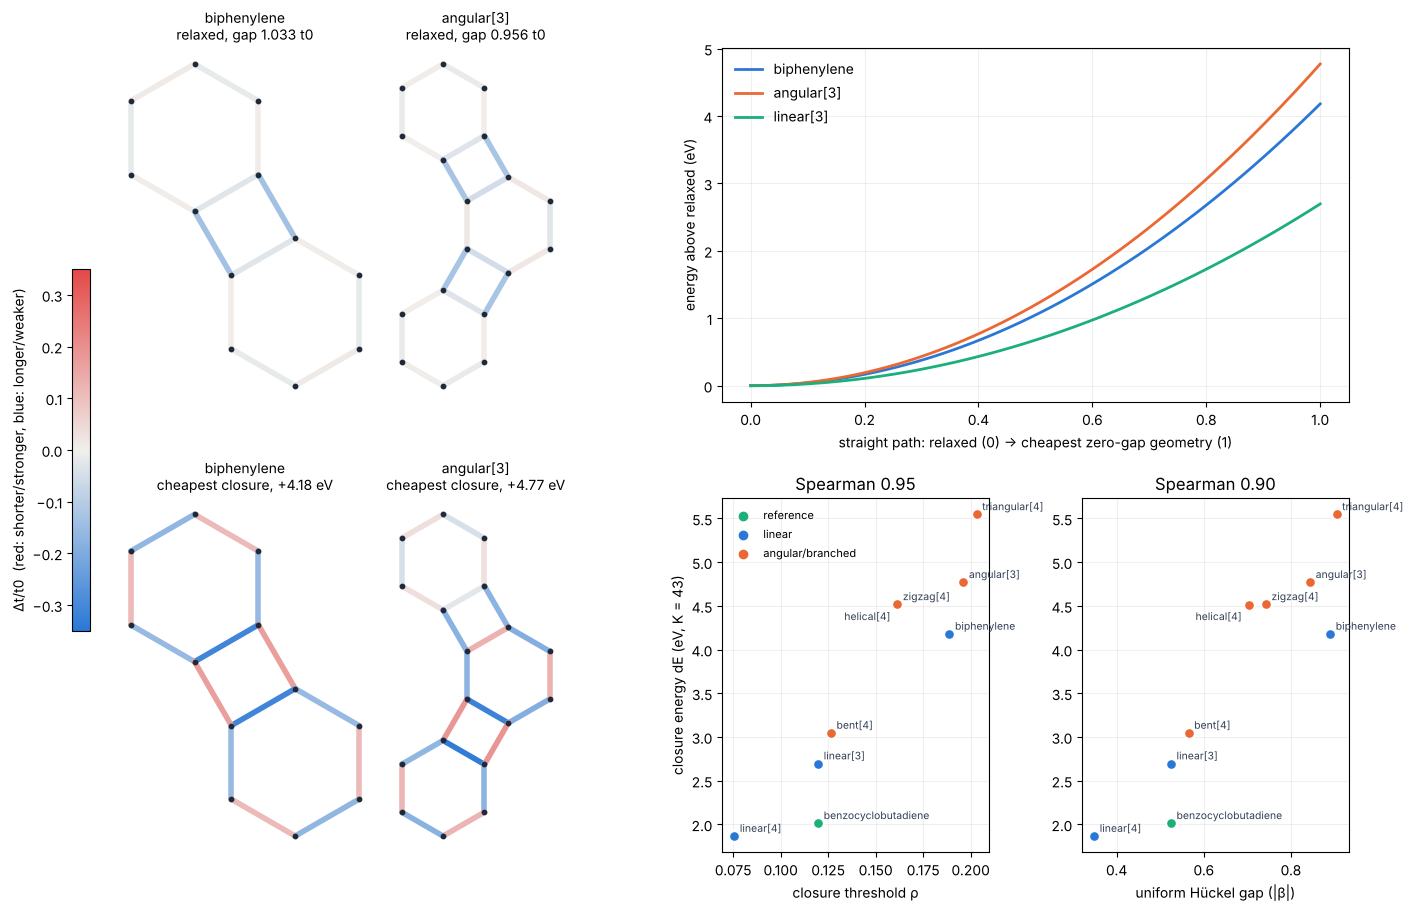

In [13]:
fig = plt.figure(figsize=(14, 9), layout='constrained')
gs = fig.add_gridspec(2, 4)
norm = TwoSlopeNorm(vcenter=0, vmin=-0.35, vmax=0.35)
for col, name in enumerate(['biphenylene', 'angular[3]']):
    h = H[name][43.0]; bm = h['bm']
    for row, key in enumerate(['dr', 'dc']):
        ax = fig.add_subplot(gs[row, col])
        draw_bonds(ax, S[name]['g'], -bm.a*h[key]/bm.t0, norm, lw=4)
        sub = f'cheapest closure, +{h["dE"]:.2f} eV' if key == 'dc' else f'relaxed, gap {h["gap_relax"]:.3f} t0'
        ax.set_title(f'{name}\n{sub}', fontsize=10)
sm = plt.cm.ScalarMappable(norm=norm, cmap=DIV)
fig.colorbar(sm, ax=fig.axes, location='left', shrink=0.45, label='Δt/t0  (red: shorter/stronger, blue: longer/weaker)')

ax = fig.add_subplot(gs[0, 2:])
for name, c in [('biphenylene', '#2a78d6'), ('angular[3]', '#eb6834'), ('linear[3]', '#1baf7a')]:
    h = H[name][43.0]; bm = h['bm']; lam = np.linspace(0, 1, 60)
    E0 = bm.energy(h['dr'])[0]
    ax.plot(lam, [bm.energy(h['dr'] + l*(h['dc']-h['dr']))[0]-E0 for l in lam], color=c, lw=2, label=name)
ax.set(xlabel='straight path: relaxed (0) → cheapest zero-gap geometry (1)', ylabel='energy above relaxed (eV)')
ax.legend(frameon=False); ax.grid(alpha=.2)

ax = fig.add_subplot(gs[1, 2])
ax2 = fig.add_subplot(gs[1, 3], sharey=ax)
for n in closing:
    c = FAMILY_COLOR[S[n]['fam']]; dE = H[n][43.0]['dE']
    for a_, x in ((ax, S[n]['rho']), (ax2, S[n]['gap'])):
        a_.scatter(x, dE, s=60, color=c, edgecolor='white', lw=1.5, zorder=3)
        off, ha = ((-5, -11), 'right') if n == 'helical[4]' else ((4, 3), 'left')
        a_.annotate(n, (x, dE), xytext=off, textcoords='offset points', fontsize=7.5, color='#334155', ha=ha)
for fam, c in FAMILY_COLOR.items(): ax.scatter([], [], color=c, label=fam)
ax.legend(frameon=False, fontsize=8, loc='upper left')
dEs = [H[n][43.0]['dE'] for n in closing]
ax.set(xlabel='closure threshold ρ', ylabel='closure energy dE (eV, K = 43)',
       title=f'Spearman {spearmanr(dEs, [S[n]["rho"] for n in closing])[0]:.2f}')
ax2.set(xlabel='uniform Hückel gap (|β|)', title=f'Spearman {spearmanr(dEs, [S[n]["gap"] for n in closing])[0]:.2f}')
for a_ in (ax, ax2): a_.grid(alpha=.2)
plt.show()

## 8. 新颖性账本与下一步

**v0.2 实际完成：** 精确、可推广的 ρ 算法，并与全顶点枚举对拍；[N]phenylene（N = 2–4）9 个骨架的精确阈值、闭合轨道位置和见证；一个可解释的谱包含关系；一个键长模型下的弛豫方向、闭合能量和参数敏感性。

**不能据此宣称：** 新的数学概念；新的芳香性理论；ρ 在同尺寸异构体上提供了 gap 之外的信息（数据显示没有）；任何关于真实分子绝对能量的预测；12%/19% 是键长变化（它们是 π 耦合变化）。

**已知理论（优先权检索的起点）：**

- 区间矩阵 regularity radius 与 Rohn 顶点判据；一般情形 NP-hard。
- Dewar–Longuet-Higgins / Wilcox 的 algebraic structure count，以及之后 Gutman、Trinajstić 等人的 ASC 文献；phenylene 和 acenylene 的 ASC 有专门计算（Graovac 等 1999）。
- 4N 环怎样影响 Hückel 能隙"动力学稳定性"，Langler（2008）专门讨论过，并提出过用结构设计调节它。这篇和本题最近，必须先读。
- Randić 共轭圈、Gineityte 对联苯撑补充共轭圈的分析；Sciriha、Fowler 等人关于奇异图、nut graph 和非键轨道的工作。

**目前可能值得留下的主张，需要验证：**

> 在含 4n 圈的交替烃里，"ASC 相消在局部键耦合扰动下的鲁棒性"刻画的是闭合难度，而弛豫后的 Hückel 能隙刻画不了。线型骨架的闭合是集体的，角型和支化骨架的闭合局域在最弱的末端单元。

**下一步，仍然只押三件事：**

1. **优先权（先做）：** 读 Langler 2008 及其引用链；检索 "algebraic structure count" 加 weighted / bond length / perturbation / robustness。若有人已做过加权 ASC 何时为零，就止损或换题。
2. **换一个更像样的闭合判据：** 闭壳层 Hückel 在 gap → 0 时不可信。改用自旋非限制的 Hubbard/PPP 平均场，或文献中已有的双自由基指数（y₀）与单重态–三重态能隙，检查 ρ 和弛豫后 gap 谁更能解释它们的排序。这一步决定"闭合难度"有没有可观测对应物。
3. **扩大样本但保持小：** N = 5 需要利用镜面对称分块（第 6 节的机制正好可以用来降维），再加几个非 phenylene 的 4n 圈交替烃，避免结论只是 phenylene 的特性。

暂不承诺发文速度，也不展开新框架、大数据库或神经网络。


## 9. 参考文献

**数学：**
- Rohn, *Forty necessary and sufficient conditions for regularity of interval matrices: A survey* (2009). [DOI:10.13001/1081-3810.1327](https://doi.org/10.13001/1081-3810.1327)。含 $(y,z)$ 顶点判据。
- Poljak & Rohn, *Checking robust nonsingularity is NP-hard*, Math. Control Signals Systems 6, 1–9 (1993). [DOI:10.1007/BF01213466](https://doi.org/10.1007/BF01213466)
- Hartman & Hladík, *Regularity radius: Properties, approximation and a not a priori exponential algorithm* (2018). [arXiv:1806.09988](https://arxiv.org/abs/1806.09988)

**化学图论：**
- Dewar & Longuet-Higgins, *The correspondence between the resonance and molecular orbital theories*, Proc. R. Soc. Lond. A 214, 482 (1952)。**卷页按记忆填写，DOI 尚未核实**（检索时被限流）。
- Wilcox, *Stability of molecules containing (4n)-rings*, Tetrahedron Lett. 9, 795–800 (1968). [DOI:10.1016/S0040-4039(01)98854-9](https://doi.org/10.1016/S0040-4039(01)98854-9)
- Wilcox, *Stability of molecules containing nonalternant rings*, J. Am. Chem. Soc. 91, 2732–2736 (1969). [DOI:10.1021/ja01038a054](https://doi.org/10.1021/ja01038a054)
- Graovac, Juvan, Mohar, Žerovnik, *Computing the determinant and the algebraic structure count in polygraphs*, Croat. Chem. Acta 72, 853–867 (1999). [hrcak.srce.hr/132304](https://hrcak.srce.hr/en/132304)
- Langler, *The complex roles of 4N and 4N + 2 rings in determining Hückel-level kinetic stabilities of even alternant hydrocarbons*, Aust. J. Chem. 61, 26–35 (2008). [DOI:10.1071/CH07217](https://doi.org/10.1071/CH07217)
- Gineityte, *Supplementary conjugated circuits for biphenylene and related hydrocarbons*. [arXiv:1602.07904](https://arxiv.org/abs/1602.07904)
- Ciesielski et al., *How to find the Fries structures for benzenoid hydrocarbons* (2010). [DOI:10.3390/sym2031390](https://doi.org/10.3390/sym2031390)
- Fowler, Pickup, Sciriha 等，*Nonbonding orbitals in fullerenes: nuts and cores in singular polyhedral graphs* (2007). [链接](https://um.edu.mt/library/oar/bitstream/123456789/28150/3/Nonbonding_orbitals_in_fullerenes_nuts_and_cores_in_singular_polyhedral_graphs_2007.pdf)

**化学与模型：**
- Vollhardt, *The phenylenes*, Pure Appl. Chem. 65, 153 (1993). [PDF](https://joomla.iupac.org/publications/pac/1993/pdf/6501x0153.pdf)
- Su, Schrieffer & Heeger, *Solitons in polyacetylene*, Phys. Rev. Lett. 42, 1698–1701 (1979). [DOI:10.1103/PhysRevLett.42.1698](https://doi.org/10.1103/PhysRevLett.42.1698)
- Moles Quintero et al., *Polycyclic hydrocarbons from [4n]annulenes* (2022). [DOI:10.1002/anie.202209138](https://doi.org/10.1002/anie.202209138)

运行环境：Python 3、NumPy、SciPy、Matplotlib。所有图结构在代码中定义，无需下载数据。按顺序执行全部代码单元。
